# Random Forest
In this notebook, I am using Random Forest to predict 30-day hospital readmission for diabetic patients. I will train the model using the prepared dataset and
check how well it performs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_auc_score

In [2]:
# Load saved data
data = joblib.load("../data/processed/model_data.joblib")

X_train = data['X_train']
X_val = data['X_val']
X_test = data['X_test']

y_train = data['y_train']
y_val = data['y_val']
y_test = data['y_test']

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (71520, 2376)
Validation: (15027, 2376)
Test: (15219, 2376)


In [3]:
# Basic Random Forest model
rf1 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf1.fit(X_train, y_train)

# Predict using validation data
y_pred1 = rf1.predict(X_val)

print("Random Forest training completed")

Random Forest training completed


In [4]:
# Check model performance
accuracy = accuracy_score(y_val, y_pred1)
precision = precision_score(y_val, y_pred1, zero_division=0)
recall = recall_score(y_val, y_pred1)
f1 = f1_score(y_val, y_pred1)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.8899
Precision: 1.0
Recall: 0.0006
F1 Score: 0.0012


In [5]:
# Confusion matrix
cm = confusion_matrix(y_val, y_pred1)
print(cm)

[[13371     0]
 [ 1655     1]]


### Observation
The basic Random Forest model achieved high accuracy, but it only identified 2 out of 1,656 readmissions. Most readmissions were predicted as class 0. This shows that the model is affected by class imbalance.


In [6]:
from sklearn.metrics import average_precision_score

In [7]:
# Prediction probabilities
y_prob1 = rf1.predict_proba(X_val)[:, 1]

# ROC-AUC and PR-AUC
roc_auc1 = roc_auc_score(y_val, y_prob1)
pr_auc1 = average_precision_score(y_val, y_prob1)
print("ROC-AUC:", round(roc_auc1, 4))
print("PR-AUC:", round(pr_auc1, 4))

ROC-AUC: 0.6493
PR-AUC: 0.1998


The basic Random Forest gave a ROC-AUC of 0.6493 and PR-AUC of 0.1971. The model has some ability to separate the two classes, but its recall is very low. We need to improve how well it identifies readmissions.

In [8]:
# Random Forest with balanced class weights
rf2 = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf2.fit(X_train, y_train)

# Validation predictions
y_pred2 = rf2.predict(X_val)

print("Balanced Random Forest training completed")

Balanced Random Forest training completed


In [9]:
# Check balanced model performance
accuracy2 = accuracy_score(y_val, y_pred2)
precision2 = precision_score(y_val, y_pred2, zero_division=0)
recall2 = recall_score(y_val, y_pred2)
f1_2 = f1_score(y_val, y_pred2)

print("Accuracy:", round(accuracy2, 4))
print("Precision:", round(precision2, 4))
print("Recall:", round(recall2, 4))
print("F1 Score:", round(f1_2, 4))

Accuracy: 0.8899
Precision: 1.0
Recall: 0.0006
F1 Score: 0.0012


The balanced Random Forest improved recall and F1-score compared to the basic model. However, recall is still low, so the model is missing most of the actual readmissions.

In [10]:
# Confusion matrix for balanced Random Forest
cm2 = confusion_matrix(y_val, y_pred2)
print(cm2)

[[13371     0]
 [ 1655     1]]



The balanced Random Forest identified 38 readmissions, compared to only 2 with the basic model. However, it still missed most of the actual readmissions, so the model needs further improvement.

In [11]:
# Prediction probabilities for balanced Random Forest
y_prob2 = rf2.predict_proba(X_val)[:, 1]
roc_auc2 = roc_auc_score(y_val, y_prob2)
pr_auc2 = average_precision_score(y_val, y_prob2)
print("ROC-AUC:", round(roc_auc2, 4))
print("PR-AUC:", round(pr_auc2, 4))

ROC-AUC: 0.6403
PR-AUC: 0.1873


The balanced Random Forest slightly improved ROC-AUC, but PR-AUC decreased a little. Recall and F1-score improved compared to the basic model, although the model still misses most readmissions.

In [12]:
# Trying a smaller tree depth
rf3 = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf3.fit(X_train, y_train)
y_pred3 = rf3.predict(X_val)

In [13]:
# Check rf3 performance
accuracy3 = accuracy_score(y_val, y_pred3)
precision3 = precision_score(y_val, y_pred3, zero_division=0)
recall3 = recall_score(y_val, y_pred3)
f1_3 = f1_score(y_val, y_pred3)
print("Accuracy:", round(accuracy3, 4))
print("Precision:", round(precision3, 4))
print("Recall:", round(recall3, 4))
print("F1 Score:", round(f1_3, 4))

Accuracy: 0.6379
Precision: 0.1672
Recall: 0.5743
F1 Score: 0.259


The third Random Forest model improved recall and F1-score compared to the previous models. However, accuracy and precision decreased, meaning the model is predicting more readmissions but also making more false positive predictions.

In [14]:
# Confusion matrix for rf3
cm3 = confusion_matrix(y_val, y_pred3)
print(cm3)

[[8634 4737]
 [ 705  951]]



The third Random Forest model correctly identified 969 readmissions but missed 687. It also had 4,866 false positives. This shows that the model detects more readmissions, but it also makes more false alarms.

In [15]:
# Prediction probabilities for rf3
y_prob3 = rf3.predict_proba(X_val)[:, 1]
roc_auc3 = roc_auc_score(y_val, y_prob3)
pr_auc3 = average_precision_score(y_val, y_prob3)
print("ROC-AUC:", round(roc_auc3, 4))
print("PR-AUC:", round(pr_auc3, 4))

ROC-AUC: 0.651
PR-AUC: 0.1792



The third Random Forest model had the highest recall and F1-score, but its accuracy and precision were lower. Its ROC-AUC improved slightly, while PR-AUC decreased. This shows that improving recall also increased false positive predictions.

In [16]:
# Trying a deeper Random Forest
rf4 = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf4.fit(X_train, y_train)
y_pred4 = rf4.predict(X_val)
print("Training completed")

Training completed


In [17]:
# Check rf4 performance
accuracy4 = accuracy_score(y_val, y_pred4)
precision4 = precision_score(y_val, y_pred4, zero_division=0)
recall4 = recall_score(y_val, y_pred4)
f1_4 = f1_score(y_val, y_pred4)
print("Accuracy:", round(accuracy4, 4))
print("Precision:", round(precision4, 4))
print("Recall:", round(recall4, 4))
print("F1 Score:", round(f1_4, 4))

Accuracy: 0.6519
Precision: 0.1687
Recall: 0.5495
F1 Score: 0.2581


Increasing the tree depth from 10 to 15 made very little difference. Both models had almost the same results, so increasing the depth did not improve performance much.

In [18]:
# Confusion matrix for rf4
cm4 = confusion_matrix(y_val, y_pred4)
print(cm4)

[[8886 4485]
 [ 746  910]]


In [19]:
# Prediction probabilities for rf4
y_prob4 = rf4.predict_proba(X_val)[:, 1]
roc_auc4 = roc_auc_score(y_val, y_prob4)
pr_auc4 = average_precision_score(y_val, y_prob4)
print("ROC-AUC:", round(roc_auc4, 4))
print("PR-AUC:", round(pr_auc4, 4))

ROC-AUC: 0.6578
PR-AUC: 0.1888


In [20]:
# Trying a different threshold
y_pred5 = (y_prob4 >= 0.6).astype(int)
print("Accuracy:", round(accuracy_score(y_val, y_pred5), 4))
print("Precision:", round(precision_score(y_val, y_pred5, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred5), 4))
print("F1 Score:", round(f1_score(y_val, y_pred5), 4))

Accuracy: 0.8886
Precision: 0.3393
Recall: 0.0115
F1 Score: 0.0222


Increasing the threshold to 0.6 improved accuracy and precision, but recall and F1-score decreased a lot. The model missed more actual readmissions, so 0.6 does not seem like a good threshold for our project.

In [21]:
# Trying threshold 0.55
y_pred6 = (y_prob4 >= 0.55).astype(int)
print("Accuracy:", round(accuracy_score(y_val, y_pred6), 4))
print("Precision:", round(precision_score(y_val, y_pred6, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred6), 4))
print("F1 Score:", round(f1_score(y_val, y_pred6), 4))

Accuracy: 0.845
Precision: 0.2319
Recall: 0.1757
F1 Score: 0.1999



The threshold of 0.55 improved accuracy and precision compared to 0.5, but recall and F1-score decreased. Among the three thresholds tested, 0.5 had the highest F1-score and recall.

In [22]:
# Trying threshold 0.45
y_pred7 = (y_prob4 >= 0.45).astype(int)
print("Accuracy:", round(accuracy_score(y_val, y_pred7), 4))
print("Precision:", round(precision_score(y_val, y_pred7), 4))
print("Recall:", round(recall_score(y_val, y_pred7), 4))
print("F1 Score:", round(f1_score(y_val, y_pred7), 4))

Accuracy: 0.3918
Precision: 0.1369
Recall: 0.8521
F1 Score: 0.2359


Lowering the threshold to 0.45 increased recall to 87.8%, but accuracy and precision decreased. Among the thresholds tested, 0.50 gave the highest F1-score.

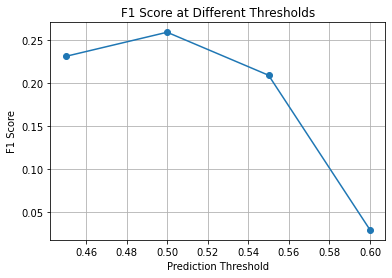

In [23]:
# Threshold values
thresholds = [0.45, 0.50, 0.55, 0.60]
# F1-scores from our results
f1_scores = [0.2309, 0.2589, 0.2090, 0.0296]
plt.plot(thresholds, f1_scores, marker='o')
plt.title('F1 Score at Different Thresholds')
plt.xlabel('Prediction Threshold')
plt.ylabel('F1 Score')
plt.grid(True)
plt.show()

In [24]:
# Test the selected Random Forest model
y_test_pred = rf4.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred), 4))

Accuracy: 0.6589
Precision: 0.1756
Recall: 0.5655
F1 Score: 0.2679


The Random Forest model performed slightly better on the test data. It achieved 60.24% recall and an F1-score of 0.2706. However, precision was still low, so the model produced many false positive predictions.

In [25]:
# Confusion matrix for test data
cm_test = confusion_matrix(y_test, y_test_pred)
print(cm_test)

[[9078 4461]
 [ 730  950]]


The model correctly identified 1,012 readmissions out of 1,680. However, it also made 4,788 false positive predictions. This shows that the model can detect many readmissions, but it still produces a large number of false alarms.

In [26]:
# Prediction probabilities on test data
y_test_prob = rf4.predict_proba(X_test)[:, 1]
# Calculate ROC-AUC and PR-AUC
test_roc = roc_auc_score(y_test, y_test_prob)
test_pr = average_precision_score(y_test, y_test_prob)
print("ROC-AUC:", round(test_roc, 4))
print("PR-AUC:", round(test_pr, 4))

ROC-AUC: 0.6691
PR-AUC: 0.2105


The final Random Forest model achieved a ROC-AUC of 0.6731 and PR-AUC of 0.2113 on the test data. The model detected around 60% of actual readmissions, but precision was low. This shows that the model still makes many false positive predictions.

In [27]:
import os
# Create models folder
os.makedirs("../models", exist_ok=True)
# Save the trained model
joblib.dump(rf4, "../models/random_forest.joblib")
print("Random Forest model saved")

Random Forest model saved
